<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 04 · The model zoo

hopforge ships 28 published models. All are ordinary `Model` objects, so everything in
the other tutorials (bands, ribbons, topology, Kubo) works on them, and you can modify them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline

In [2]:
names = M.list_models()

hopforge model library:
  1D  chain                monatomic chain
  1D  ssh                  Su-Schrieffer-Heeger chain (winding number)
  1D  rice_mele            Rice-Mele chain (Thouless pumping)
  1D  kitaev_chain         Kitaev p-wave superconducting chain (Majoranas)
  1D  creutz_ladder        Creutz ladder (flat bands, AB caging)
  2D  square               square lattice
  2D  triangular           triangular lattice
  2D  honeycomb            graphene / hBN honeycomb
  2D  haldane              Haldane Chern insulator
  2D  kane_mele            Kane-Mele quantum spin Hall insulator
  2D  qwz                  Qi-Wu-Zhang Chern insulator
  2D  bhz                  Bernevig-Hughes-Zhang HgTe quantum well
  2D  kagome               kagome lattice (+ Guo-Franz SOC)
  2D  lieb                 Lieb lattice (flat band)
  2D  checkerboard         checkerboard / planar pyrochlore
  2D  dice                 alpha-T3 / dice lattice
  2D  bilayer_graphene     AB bilayer graphene with bias
  

## 1D: SSH, Rice-Mele, Kitaev, Creutz

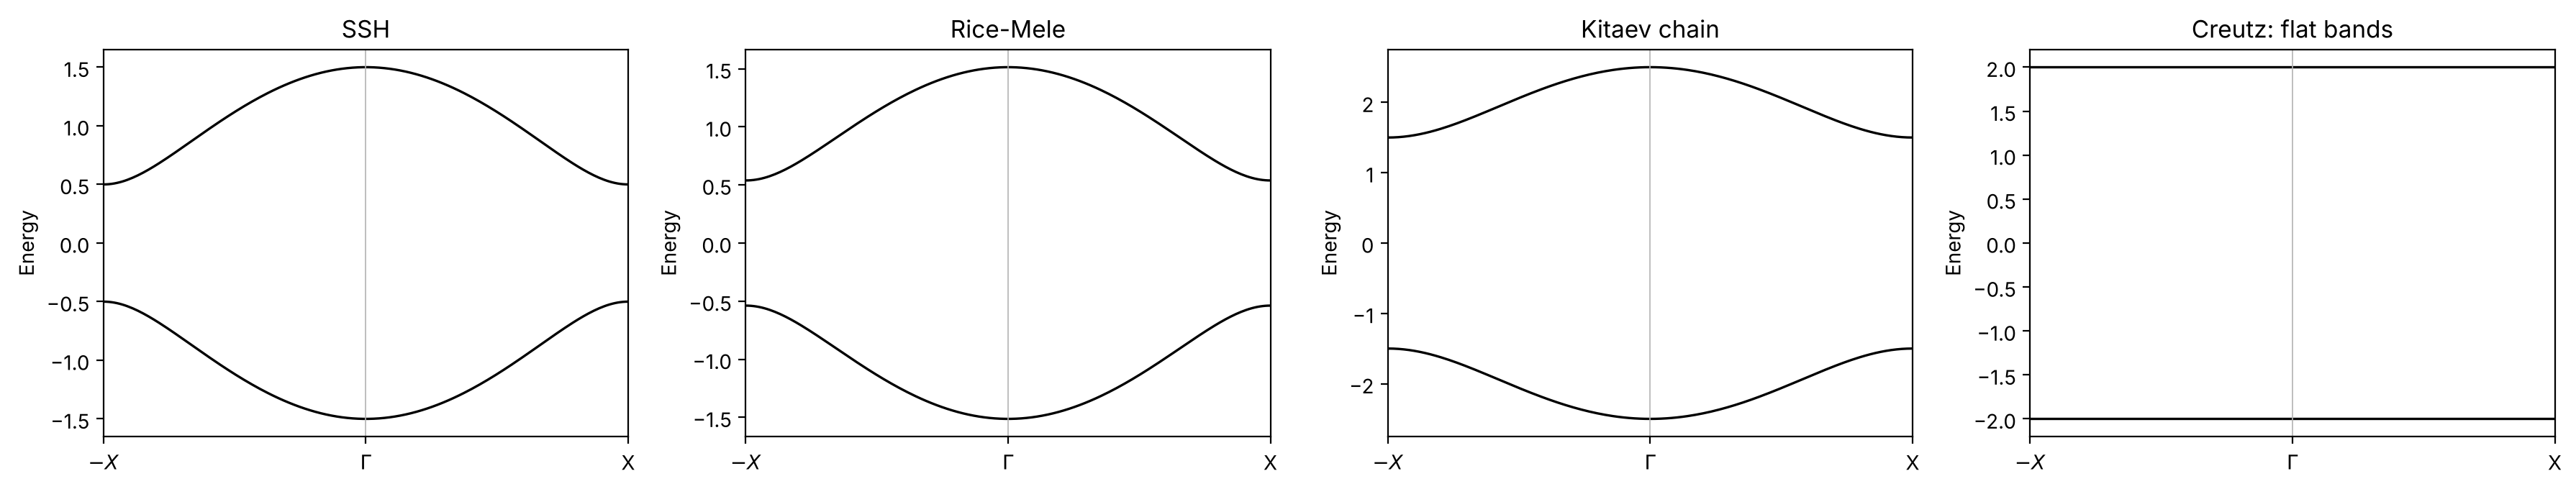

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
M.ssh(0.5, 1).plot_bands(ax=axes[0])
M.rice_mele().plot_bands(ax=axes[1])
M.kitaev_chain(mu=0.5).plot_bands(ax=axes[2])
M.creutz_ladder().plot_bands(ax=axes[3], title="Creutz: flat bands")
plt.tight_layout()

In [4]:
# Majorana end modes of an open Kitaev chain
for mu in (0.5, 3.0):
    E = np.sort(np.abs(M.kitaev_chain(mu=mu).finite(40).energies()))
    print(f"mu = {mu}: two smallest |E| = {E[:2]}")

mu = 0.5: two smallest |E| = [1.01146013e-16 3.55232055e-16]
mu = 3.0: two smallest |E| = [1.01589943 1.01589943]


## 2D Dirac and flat-band lattices

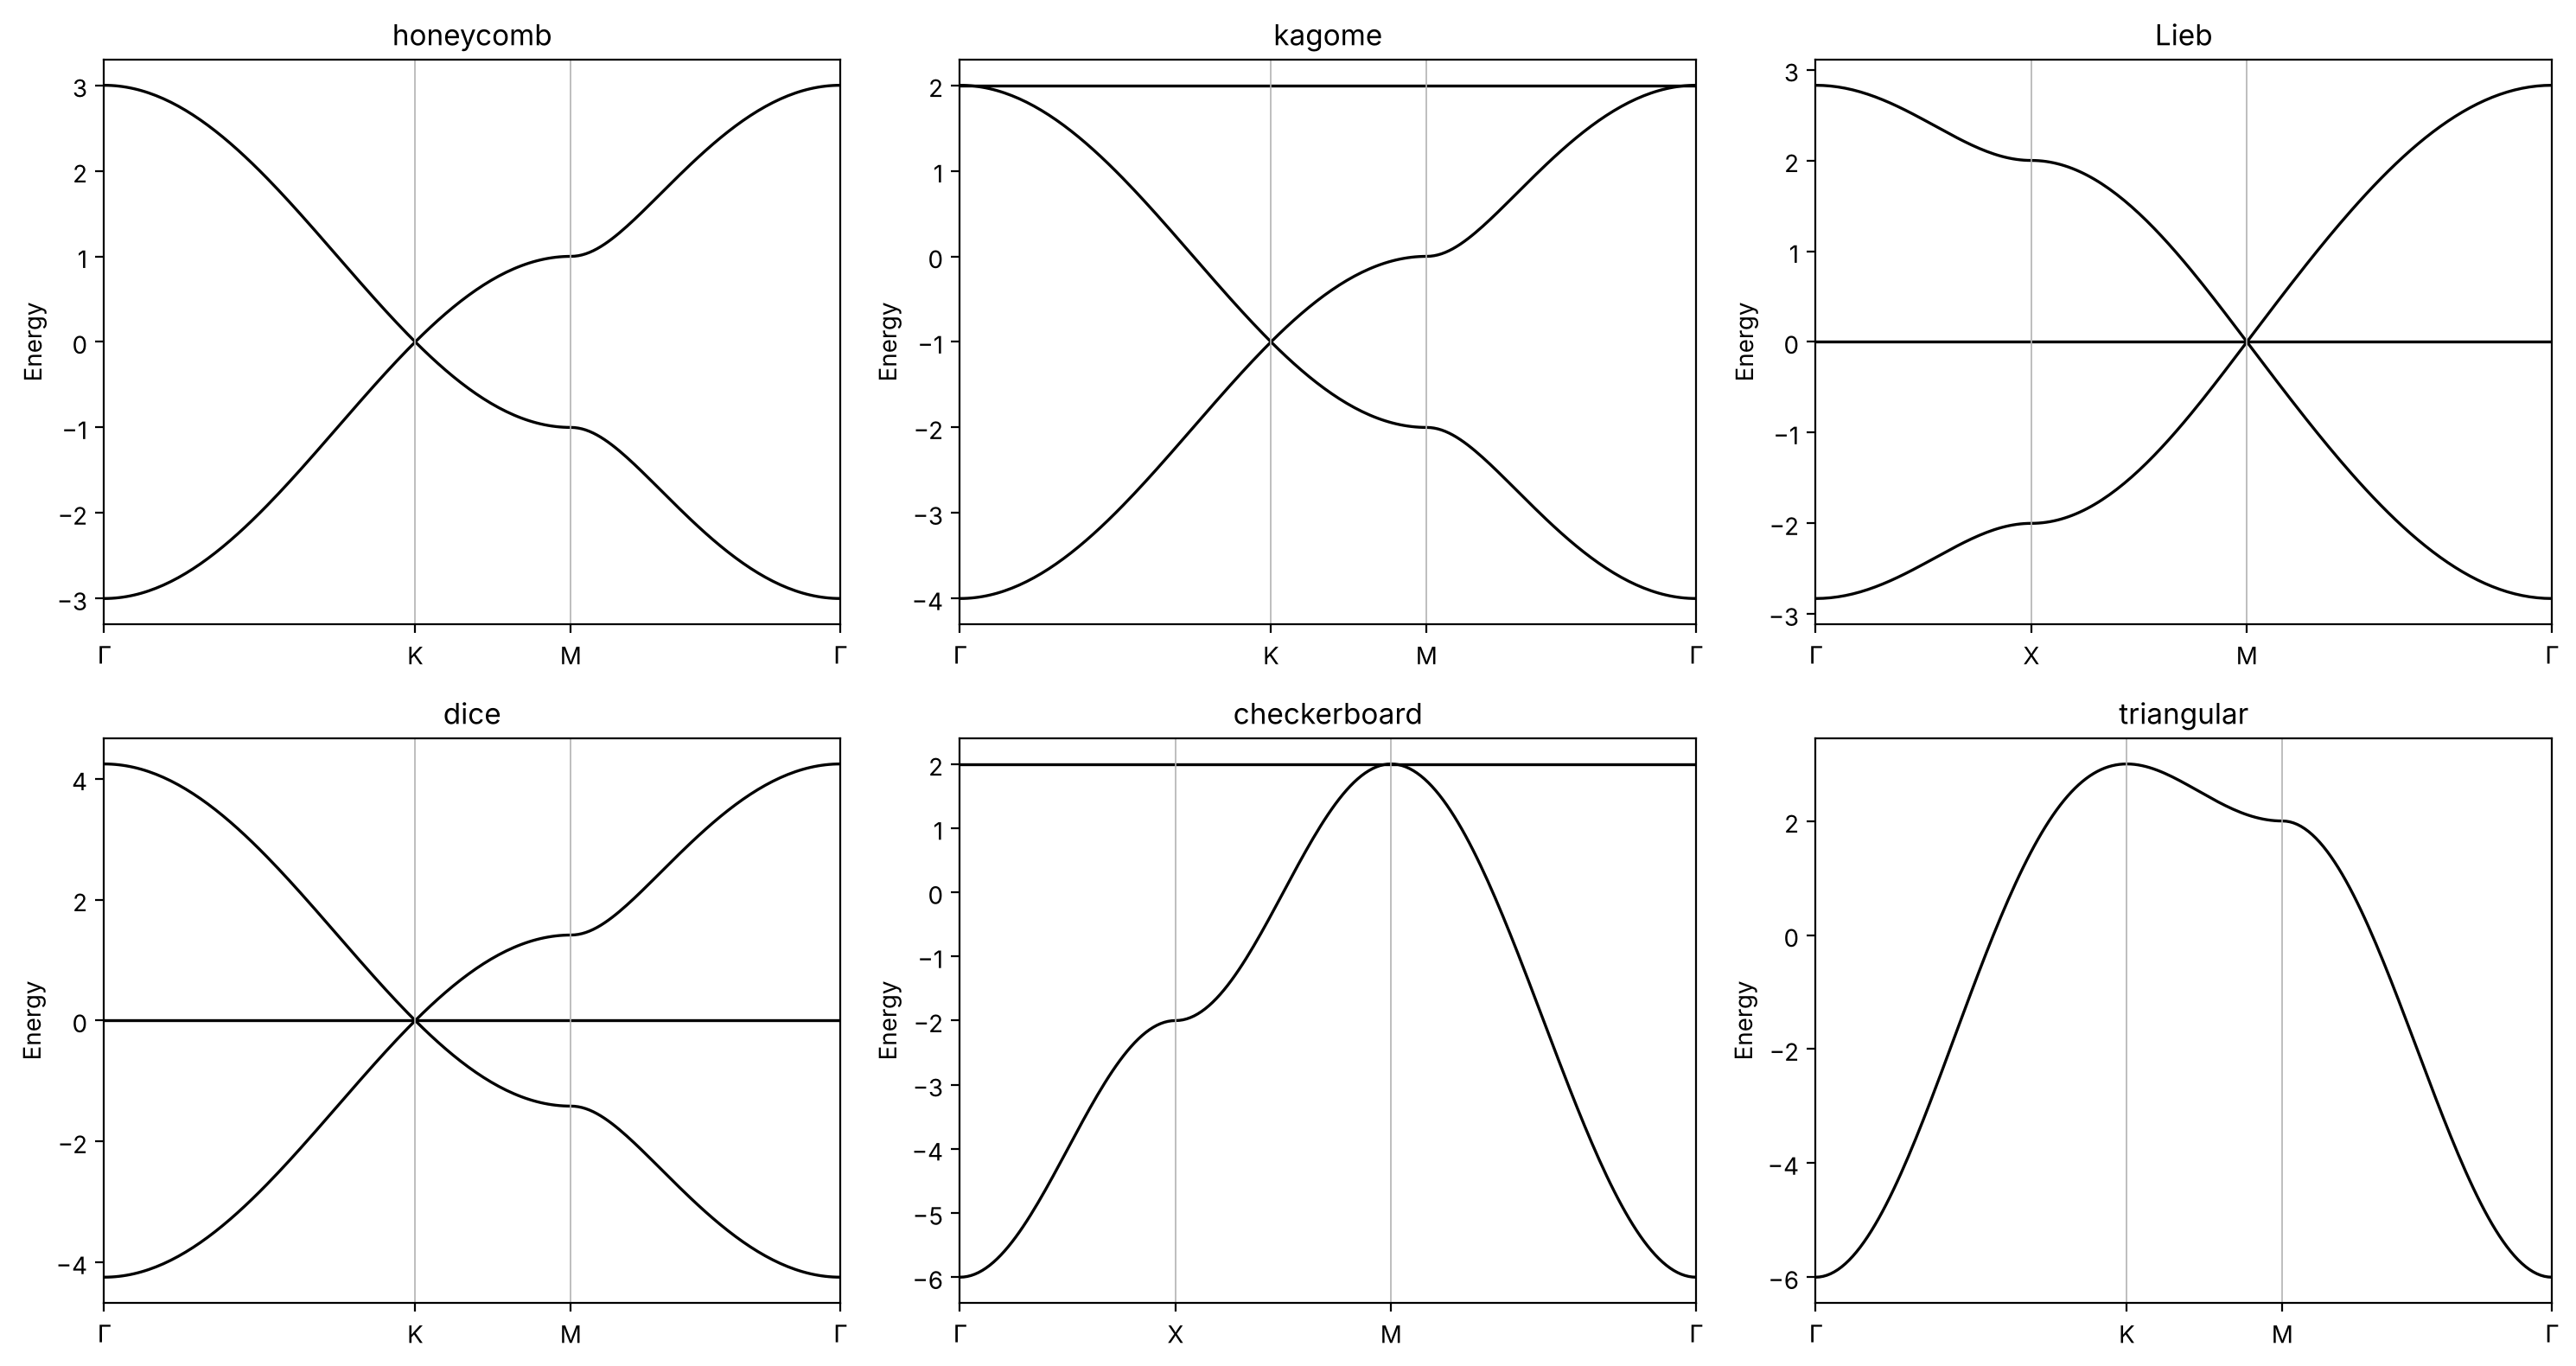

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, m in zip(axes.ravel(), [M.honeycomb(), M.kagome(), M.lieb(), M.dice(), M.checkerboard(), M.triangular()]):
    m.plot_bands(ax=ax)
plt.tight_layout()

## Topological 2D models: Haldane, Kane-Mele, QWZ, BHZ

In [6]:
for m, occ in [(M.haldane(), 1), (M.qwz(1.0), 1)]:
    print(f"{m.name:12s}  C  = {hf.chern_number(m, occ):+.0f}")
for m in [M.kane_mele(), M.bhz()]:
    print(f"{m.name:12s}  Z2 = {hf.z2_invariant(m, 2)}")

Haldane       C  = +1
QWZ           C  = -1


Kane-Mele     Z2 = 1
BHZ           Z2 = 1


## Magnetism: Rashba ferromagnet and d-wave altermagnet

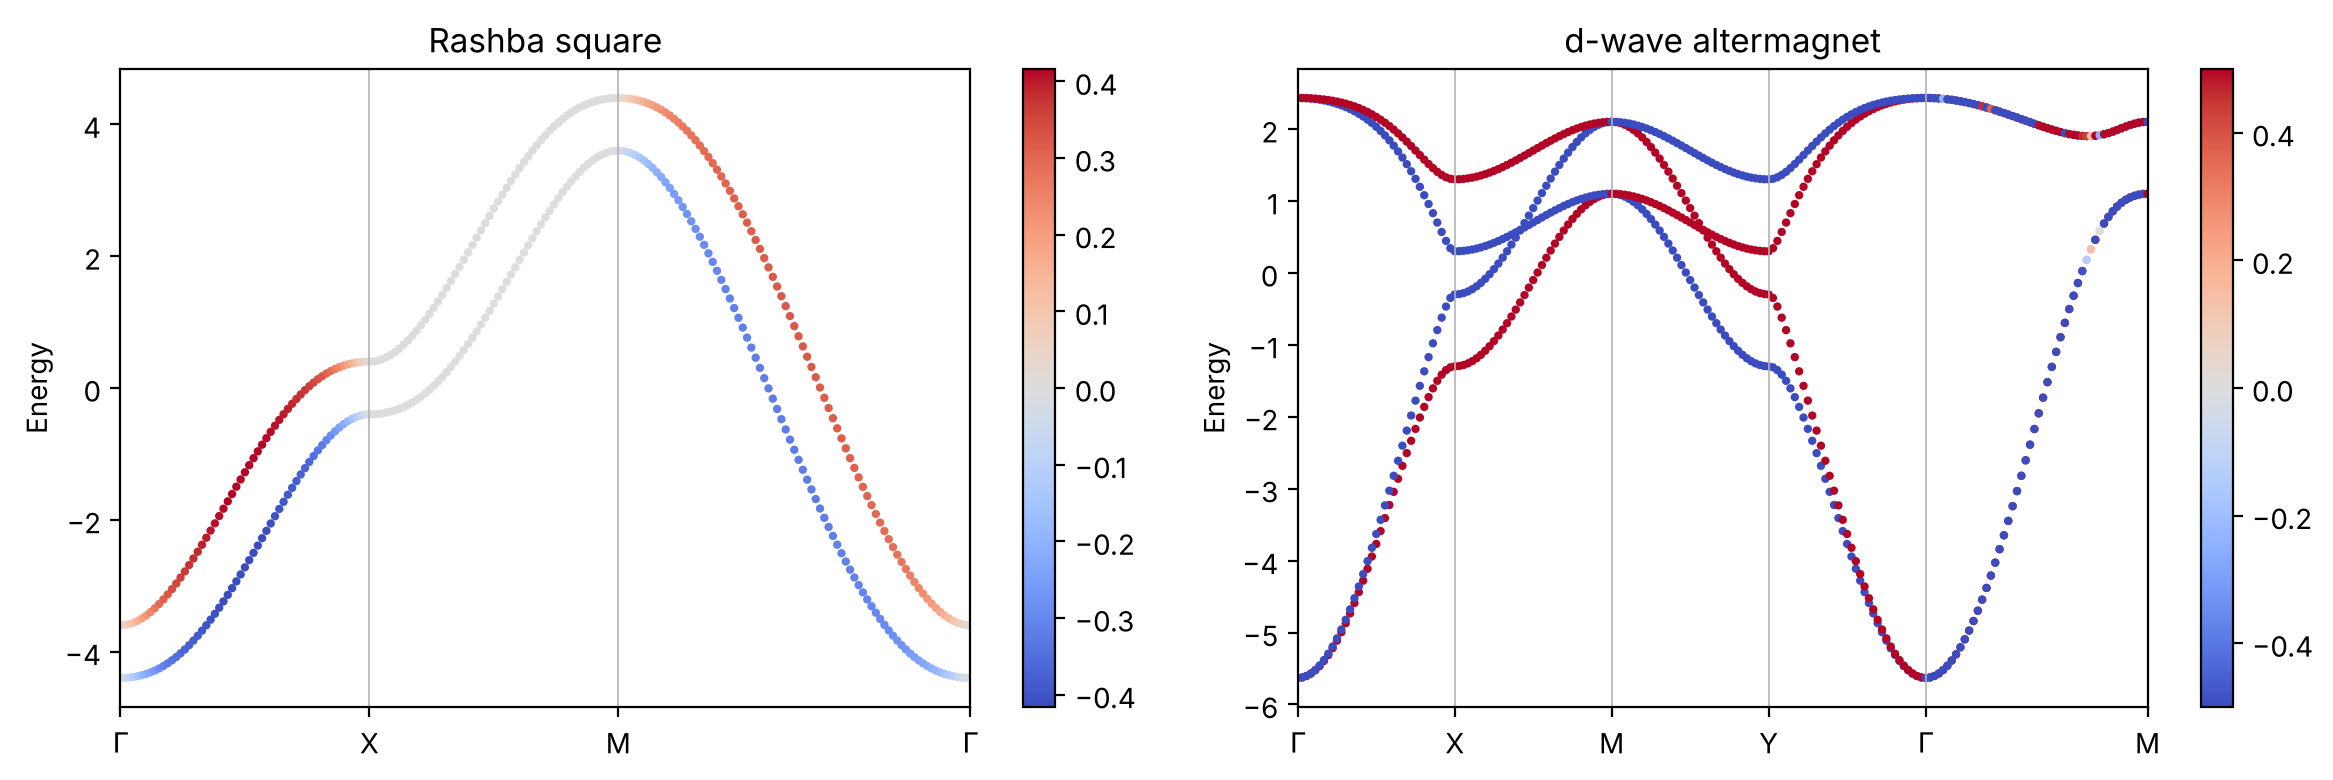

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rm = M.rashba_square(J=0.4); rm.plot_bands(ax=axes[0], weights=rm.spin_operator('y'))
am = M.altermagnet_dwave(); am.plot_bands(ax=axes[1], weights=am.spin_operator('z'))
plt.tight_layout()

## 3D: TIs, Weyl semimetal, flat-band pyrochlore

Wilson-Dirac TI (nu0;nu1nu2nu3): (1, 0, 0, 0)
Fu-Kane-Mele diamond          : (1, 1, 1, 1)


Weyl: C(kz=0) = -1  C(kz=1/2) = 0


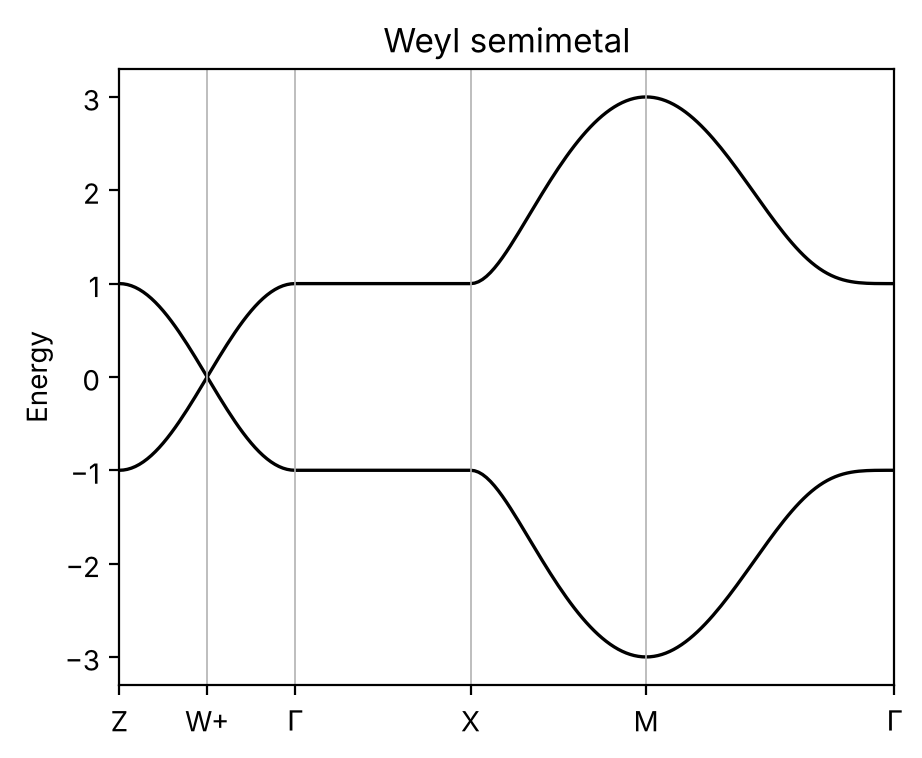

In [8]:
print("Wilson-Dirac TI (nu0;nu1nu2nu3):", hf.z2_3d(M.wilson_dirac_ti(), 2, nk=30, nscan=31))
print("Fu-Kane-Mele diamond          :", hf.z2_3d(M.diamond_fkm(), 2, nk=30, nscan=31))
w = M.weyl_minimal()
print("Weyl: C(kz=0) =", round(hf.chern_number(w, 1, fixed={2: 0.0})), " C(kz=1/2) =", round(hf.chern_number(w, 1, fixed={2: 0.5})))
w.plot_bands();

## Orbital physics: p-orbital square lattice

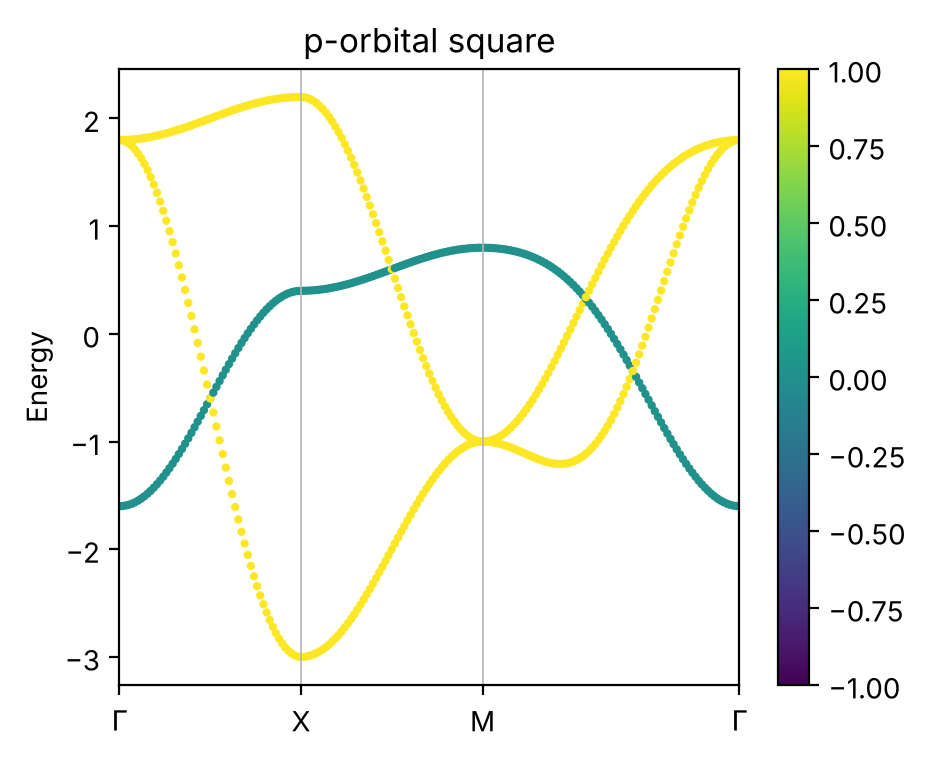

In [9]:
po = M.p_orbital_square()
po.plot_bands(weights=po.orbital_operator('z') @ po.orbital_operator('z'), cmap='viridis');

## Build by name with custom parameters

In [10]:
m = M.get("haldane", t2=0.2, phi=np.pi/3, M=0.1)
print(m.summary())

hopforge Model 'Haldane'
  periodic dims : 2   (space dim 2)
  orbitals      : 2  ['A', 'B']
  spinful       : False  -> 2 bands
  hopping terms : 9 (+ h.c.)
  special points: ['G', 'K', "K'", 'M']


## Exercises
1. Map the Haldane phase diagram C(M, φ) on a 15×15 grid.
2. Increase the Kane-Mele Rashba term until the gap closes; what happens to Z2?
3. Find the parameter where the BHZ model changes from C_up = 1 to C_up = -1.

---
## Quiz 04: The model zoo

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [11]:
quiz = hf.Quiz(4)
quiz.interactive()

In [12]:
quiz.show()

=== Quiz 04: The model zoo: canonical published Hamiltonians ===

Q1. The SSH chain is topological when
   (a) |v| > |w|
   (b) |w| > |v| (inter-cell > intra-cell)
   (c) v = w
   (d) always

Q2. The SSH model has which symmetry protecting its winding number?
   (a) none
   (b) inversion only
   (c) time reversal only
   (d) chiral (sublattice) symmetry

Q3. The Rice-Mele model adds to SSH
   (a) a staggered potential +-delta
   (b) a magnetic field
   (c) spin-orbit coupling
   (d) NNN hopping

Q4. The Kitaev chain is in its topological phase for
   (a) Delta = 0
   (b) |mu| < 2|t| (with Delta != 0)
   (c) mu = 0 only
   (d) |mu| > 2|t|

Q5. In hopforge's Kitaev chain the basis (e, h) means
   (a) electron and hole (Bogoliubov-de Gennes) components
   (b) spin up and down
   (c) two atoms
   (d) two layers

Q6. The Haldane model realises
   (a) a Weyl semimetal
   (b) a superconductor
   (c) a Chern insulator without net magnetic field
   (d) a QSH insulator

Q7. In the Haldane model 

In [13]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0